In [ ]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms

import matplotlib.pyplot as plt
import numpy as np
import random

seed = 42

random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed(seed)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

In [ ]:

import numpy as np
import torch



In [2]:
print("Pytorch Version: ", torch.__version__)
print("CUDA Available: ", torch.cuda.is_available())

device= torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:" , device)

Pytorch Version:  2.10.0+cu126
CUDA Available:  True
Device: cuda


In [3]:
transform= transforms.ToTensor()

train_dataset= torchvision.datasets.CIFAR10(
    root="./data",
    download= True,
    transform=transform,
    train=True
)

test_dataset= torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    transform=transform,
    download=True
)

print("Training samples: ", len(train_dataset))
print("Testing samples: ", len(test_dataset))

Training samples:  50000
Testing samples:  10000


In [4]:
train_loader=torch.utils.data.DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

test_loader= torch.utils.data.DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

In [5]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1=nn.Conv2d(in_channels=3,
                             out_channels=32,
                             kernel_size=3,
                             padding=1)

        self.bn1=nn.BatchNorm2d(32)
        self.relu=nn.ReLU()

        self.conv2=nn.Conv2d(in_channels=32,
                             out_channels=64,
                             kernel_size=3,
                             padding=1)

        self.bn2=nn.BatchNorm2d(64)

        self.conv3= nn.Conv2d(64,128,kernel_size=3, padding=1)
        self.bn3=nn.BatchNorm2d(128)
        self.gap=nn.AdaptiveAvgPool2d((1,1))

        self.fc=nn.Linear(128,10)


    def forward(self, x):
        x=self.conv1(x)
        x=self.bn1(x)
        x=self.relu(x)

        x=self.conv2(x)
        x=self.bn2(x)
        x=self.relu(x)

        x=self.conv3(x)
        x=self.bn3(x)
        x-self.relu(x)

        x=self.gap(x)
        x=torch.flatten(x,1)

        x=self.fc(x)

        return x



In [6]:
model=SmallCNN().to(device)

criterion=nn.CrossEntropyLoss()

optimizer=torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

In [7]:
num_epochs = 10

for epoch in range(num_epochs):

    model.train()
    running_loss = 0.0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    train_loss = running_loss / len(train_loader)

    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            _, predicted = torch.max(outputs, dim=1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Loss: {train_loss:.4f} "
        f"Test Accuracy: {accuracy:.2f}%"
    )

Epoch [1/10] Loss: 1.5517 Test Accuracy: 44.16%
Epoch [2/10] Loss: 1.3112 Test Accuracy: 43.60%
Epoch [3/10] Loss: 1.2228 Test Accuracy: 42.90%
Epoch [4/10] Loss: 1.1676 Test Accuracy: 50.24%
Epoch [5/10] Loss: 1.1251 Test Accuracy: 51.26%
Epoch [6/10] Loss: 1.0856 Test Accuracy: 55.77%
Epoch [7/10] Loss: 1.0580 Test Accuracy: 50.98%
Epoch [8/10] Loss: 1.0351 Test Accuracy: 53.28%
Epoch [9/10] Loss: 1.0124 Test Accuracy: 49.36%
Epoch [10/10] Loss: 0.9954 Test Accuracy: 55.13%


In [8]:
misclassified = []

model.eval()

with torch.no_grad():
    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        

        probabilities = torch.softmax(outputs, dim=1)
       
        confidences, predictions = torch.max(probabilities, dim=1)
        # print("Predictions: ", predictions ,", confidence:", confidences)
        for i in range(len(labels)):
            if predictions[i] != labels[i]:
                misclassified.append({
                    "image": images[i].cpu(),
                    "true_label": labels[i].item(),
                    "predicted_label": predictions[i].item(),
                    "confidence": confidences[i].item()
                })

print("Number of misclassified images:", len(misclassified))

Number of misclassified images: 4487


In [9]:
classes=[
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck"
    ]

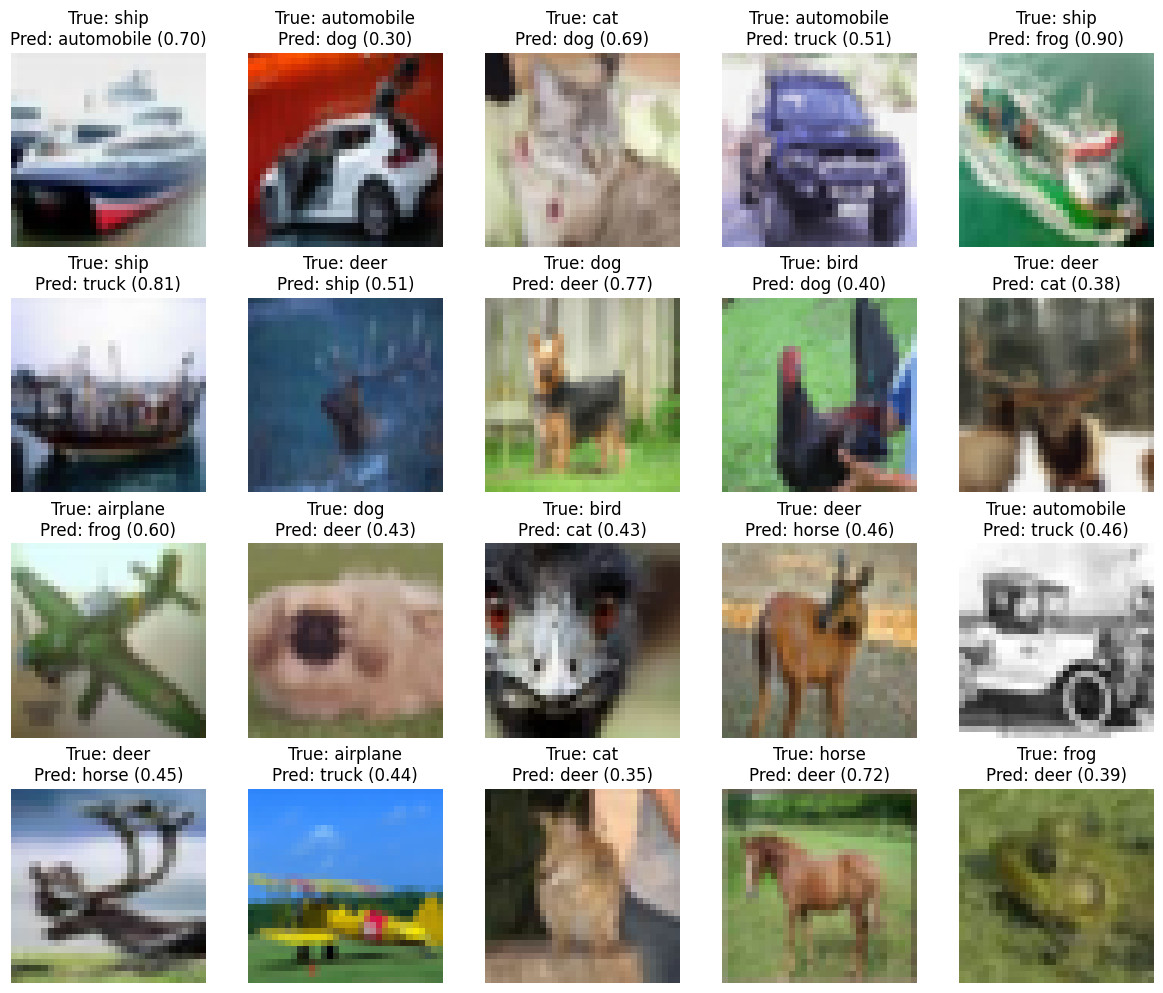

In [10]:
fig, axes = plt.subplots(4, 5, figsize=(12, 10))

for ax, item in zip(axes.flat, misclassified[:20]):

    image = item["image"]
    image = image.permute(1, 2, 0)

    ax.imshow(image)

    true_class = classes[item["true_label"]]
    predicted_class = classes[item["predicted_label"]]
    confidence = item["confidence"]

    ax.set_title(
        f"True: {true_class}\n"
        f"Pred: {predicted_class} ({confidence:.2f})"
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

In [11]:
from collections import Counter

confusion_pairs = Counter()

for item in misclassified:
    true_label = item["true_label"]
    predicted_label = item["predicted_label"]

    confusion_pairs[(true_label, predicted_label)] += 1

# print(confusion_pairs)

print("Most common mistakes:\n")

for (true_label, predicted_label), count in confusion_pairs.most_common(20):

    print(
        f"{classes[true_label]:10s} → "
        f"{classes[predicted_label]:10s}: "
        f"{count}"
    )

Most common mistakes:

automobile → truck     : 579
cat        → dog       : 348
bird       → deer      : 230
bird       → frog      : 173
ship       → airplane  : 158
bird       → dog       : 138
deer       → horse     : 137
dog        → horse     : 134
cat        → horse     : 127
cat        → deer      : 123
ship       → truck     : 121
cat        → frog      : 114
ship       → deer      : 106
bird       → horse     : 102
horse      → deer      : 101
frog       → deer      : 89
horse      → dog       : 83
deer       → frog      : 81
dog        → deer      : 79
airplane   → truck     : 79


In [12]:
wrong_confidences = [
    item["confidence"]
    for item in misclassified
]

print(f"Average confidence on wrong predictions: "
      f"{np.mean(wrong_confidences):.4f}")

print(f"Maximum confidence on wrong predictions: "
      f"{np.max(wrong_confidences):.4f}")

print(f"Minimum confidence on wrong predictions: "
      f"{np.min(wrong_confidences):.4f}")

Average confidence on wrong predictions: 0.5421
Maximum confidence on wrong predictions: 0.9999
Minimum confidence on wrong predictions: 0.1427


In [13]:
most_confident_errors = sorted(
    misclassified,
    key=lambda x: x["confidence"],
    reverse=True
)

for item in most_confident_errors[:10]:

    print(
        f"True: {classes[item['true_label']]}, "
        f"Predicted: {classes[item['predicted_label']]}, "
        f"Confidence: {item['confidence']:.4f}"
    )

True: automobile, Predicted: truck, Confidence: 0.9999
True: ship, Predicted: truck, Confidence: 0.9997
True: automobile, Predicted: truck, Confidence: 0.9996
True: automobile, Predicted: truck, Confidence: 0.9993
True: automobile, Predicted: truck, Confidence: 0.9993
True: cat, Predicted: truck, Confidence: 0.9992
True: automobile, Predicted: truck, Confidence: 0.9991
True: automobile, Predicted: truck, Confidence: 0.9986
True: automobile, Predicted: truck, Confidence: 0.9964
True: automobile, Predicted: truck, Confidence: 0.9952


The errors are clearly not random.
The model's confidence is not equivalent to correctness.

#### 1st Hypothesis:
##### The CNN has a systematic class confusions and can be highly confident when making certain types of errors.

In [14]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

all_predictions = []
all_labels = []

model.eval()

with torch.no_grad():
    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        predictions = torch.argmax(outputs, dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

cm = confusion_matrix(all_labels, all_predictions)

print(cm)

[[624   5  26  18  72  27  40  67  42  79]
 [ 66 198   1  14  15  23  26  72   6 579]
 [ 73   1 203  65 230 138 173 102   7   8]
 [  9   0  14 238 123 348 114 127   4  23]
 [  9   0  17  25 663  55  81 137   4   9]
 [  7   0   5  55  79 672  32 134   3  13]
 [  5   0   6  27  89  57 767  41   0   8]
 [  9   0   4  11 101  83   7 770   0  15]
 [158   7   5  10 106  18  22  30 523 121]
 [ 22   4   0   8  21  14   4  68   4 855]]


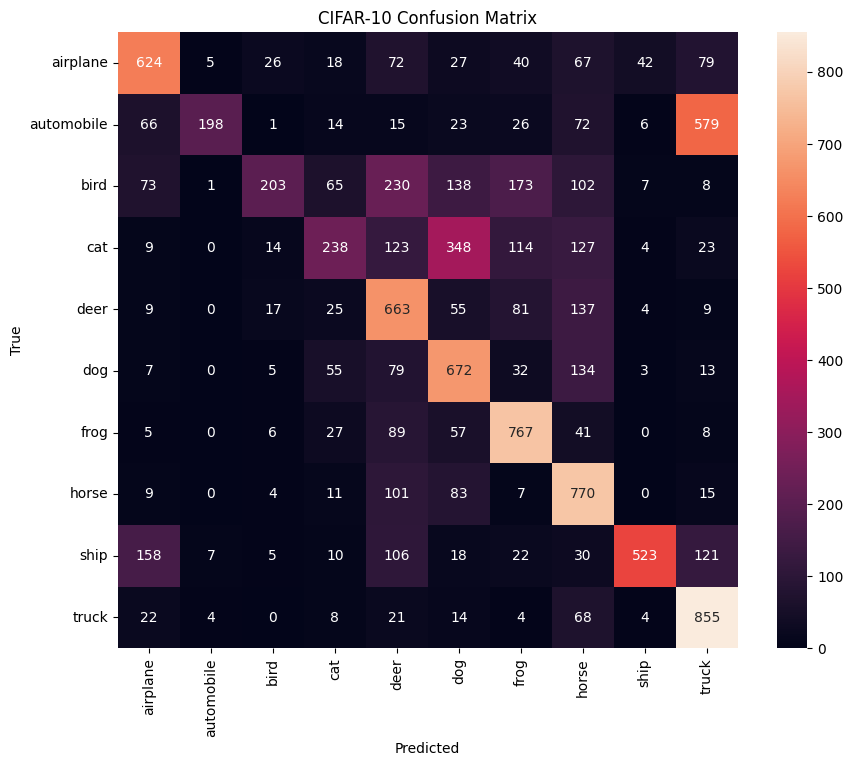

In [15]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=classes,
    yticklabels=classes
)

plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("CIFAR-10 Confusion Matrix")

plt.show()

9